# CBZ Bank customer churn model

This notebook builds the churn model for the Chapter 1 study. It follows CRISP-DM: business understanding, data understanding, preparation, modelling, evaluation, and the hand-off into the staff prototype.

The study asks for four things:

1. Engineer customer features that can predict churn.
2. Compare logistic regression, a decision tree, random forest, and XGBoost.
3. Turn the best model into a staff worklist: Retained, At-Risk Low, At-Risk Medium, At-Risk High, or Churned, with a retention action.
4. Keep the score interpretable enough for a relationship manager to act on.

The target is the `exit` flag in the study file. A customer is a churner when `exit` is true. About 18% of the 80,000 retail profiles have exited, so the class is imbalanced and recall matters as much as accuracy.


In [1]:
from pathlib import Path
import sys
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", font="DejaVu Sans")

ROOT = Path.cwd().resolve()
if not (ROOT / "bank_churn_dataset_zimbabwe_v3.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from cbz_churn.features import (
    CATEGORICAL_FEATURES,
    MODEL_FEATURES,
    NUMERIC_FEATURES,
    SNAPSHOT_DATE,
    engineer_features,
)
from cbz_churn.scoring import status_from_probability

DATA_PATH = ROOT / "bank_churn_dataset_zimbabwe_v3.csv"
FIG = ROOT / "figures"
MODEL_DIR = ROOT / "models"
FIG.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

NAVY = "#26387B"
RED = "#ED1C24"
INK = "#192965"

def save_show(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.show()

print("Study file:", DATA_PATH.name)
print("Snapshot date used for activity features:", SNAPSHOT_DATE.date())


Study file: bank_churn_dataset_zimbabwe_v3.csv
Snapshot date used for activity features: 2025-07-01


## 1. Business understanding

Chapter 1 defines churn as a customer who stops using CBZ, either by closing the account or by going quiet and moving salary and spending elsewhere. The second pattern, silent churn, is the one that matters in Zimbabwe: accounts often stay open while the relationship has already left.

The current bank process notices dormancy and closure requests after the customer has gone. This model is the earlier signal. It is a decision aid for branch staff, marketing, and relationship managers. It does not replace their judgement, and it is limited to retail profiles.


## 2. Data understanding

The file is an anonymised-style retail extract with demographics, balances in USD, tenure, product holdings, activity, and an exit flag. This section checks data quality, then explores the book before any model is fit: class balance, churn rates by profile, numeric distributions, correlation, and a closer look at composition, products, age, engagement, and recent activity.

Three fields already look like someone else's model output: `risk_score`, `risk_segment`, and `cluster_group`. Those are inspected here and then kept out of the feature set. Names are not plotted.


In [4]:
raw = pd.read_csv(DATA_PATH)
raw["churn"] = raw["exit"].astype(str).str.lower().isin(["true", "1", "yes"]).astype(int)

print(f"Rows: {len(raw):,}")
print(f"Columns: {raw.shape[1]}")
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate customer ids:", int(raw["id"].duplicated().sum()))
print(raw["churn"].value_counts().rename({0: "Stayed", 1: "Churned"}))
print("Churn rate: {:.2%}".format(raw["churn"].mean()))
print(raw.head(3).to_string())


Rows: 80,000
Columns: 26
Missing values: 0
Duplicate customer ids: 0
churn
Stayed     65600
Churned    14400
Name: count, dtype: int64
Churn rate: 18.00%
   id          full_name  credit_sco  gender  age                       occupation  balance_usd  monthly_income_usd   origin_province  tenure_ye  married  nums_card  nums_service  active_member last_active_date  last_transaction_month_usd created_date   exit customer_segment  engagement_score loyalty_level digital_behavior  risk_score risk_segment  cluster_group  churn
0   1  Kudzai Tsvangirai         725    male   55                Manager/Executive     11741.67             4094.92  Mashonaland East          0        2          4             8           True       03/04/2025                     3080.97   27/02/2025  False         Priority                90        Bronze           mobile      0.0551          Low              3      0
1   2        Last Gurure         689    male   45                 Teacher/Lecturer       801.16       

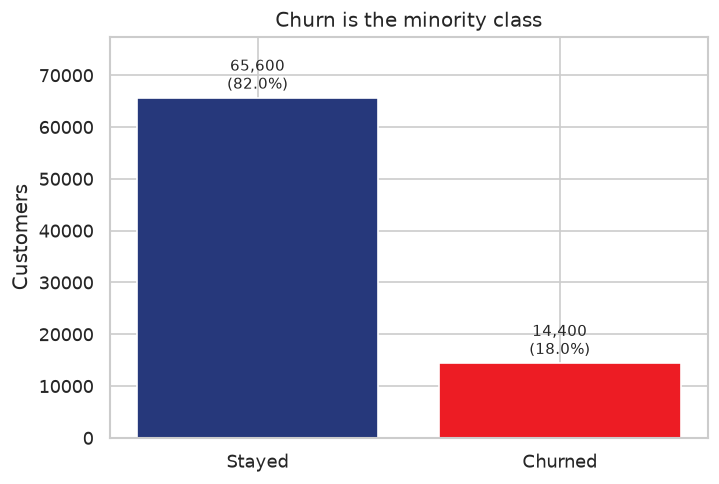

In [3]:
counts = raw["churn"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
bars = ax.bar(["Stayed", "Churned"], counts.values, color=[NAVY, RED])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 800, f"{value:,}\n({value / len(raw):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Customers")
ax.set_title("Churn is the minority class")
ax.set_ylim(0, counts.max() * 1.18)
save_show("01_class_balance")


### Churn rate by profile

These charts answer the first look at Research Question 1: which customer attributes already separate churners before any model is fit. Rates are the share of customers in that group with `exit` true. The dashed line is the book-level churn rate.


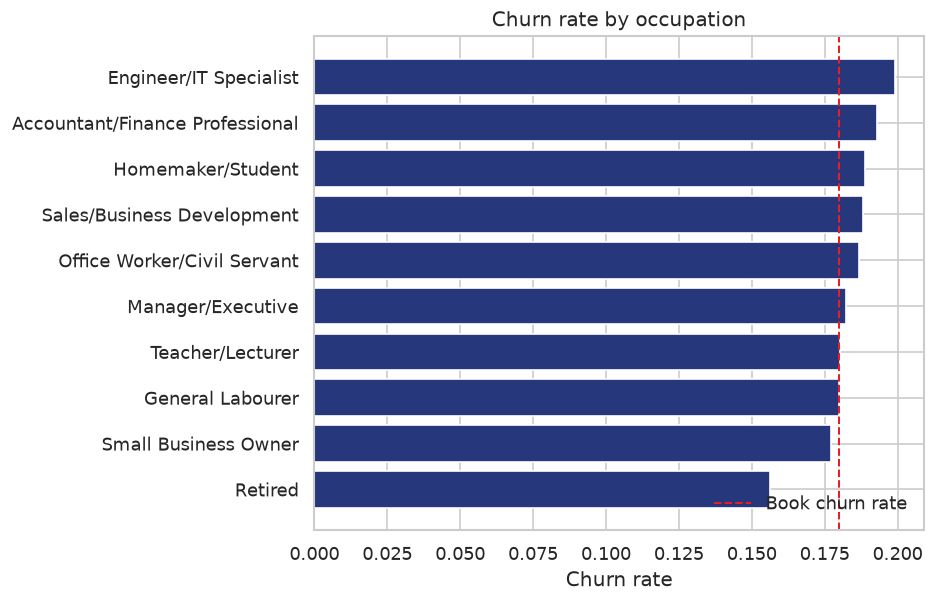

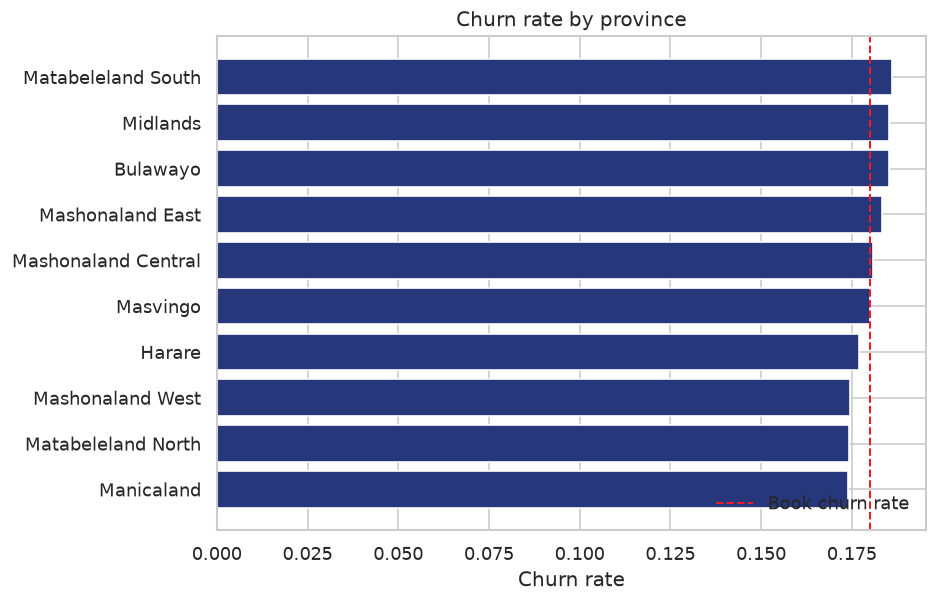

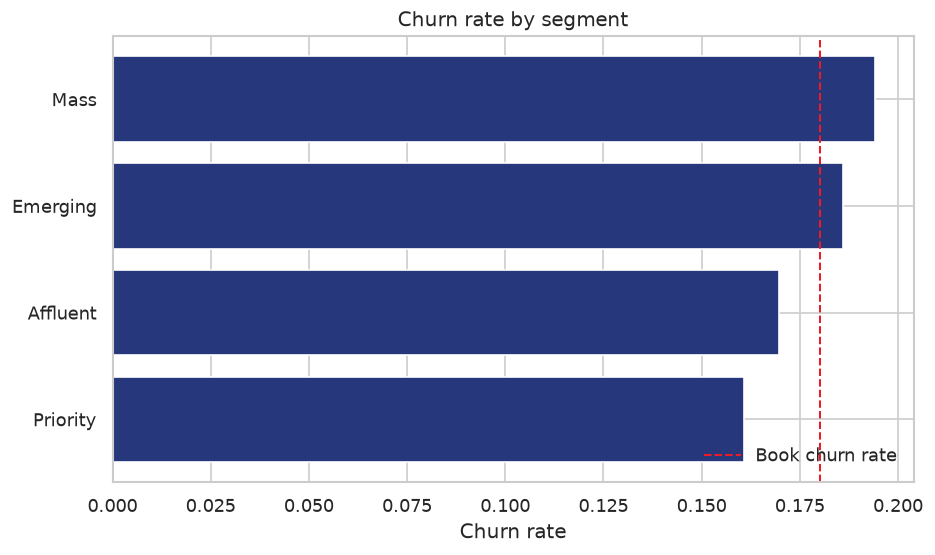

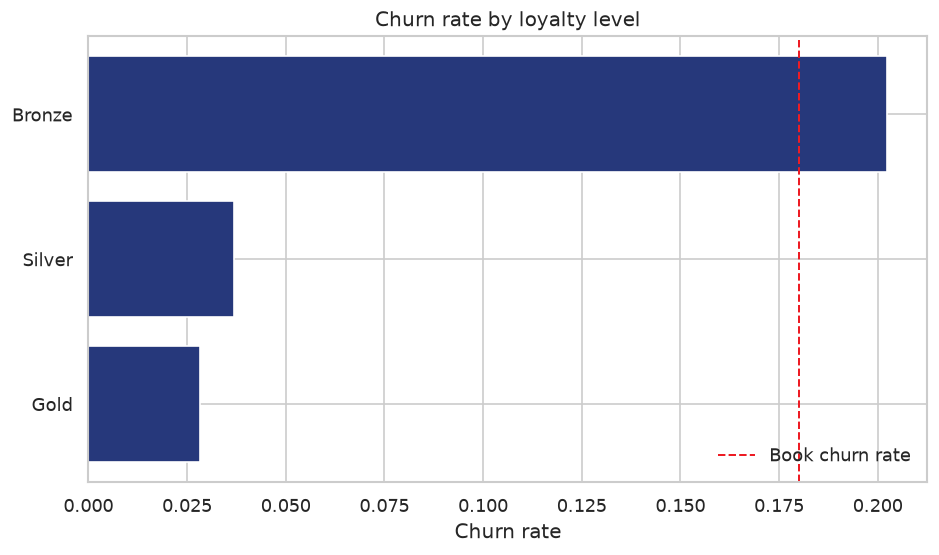

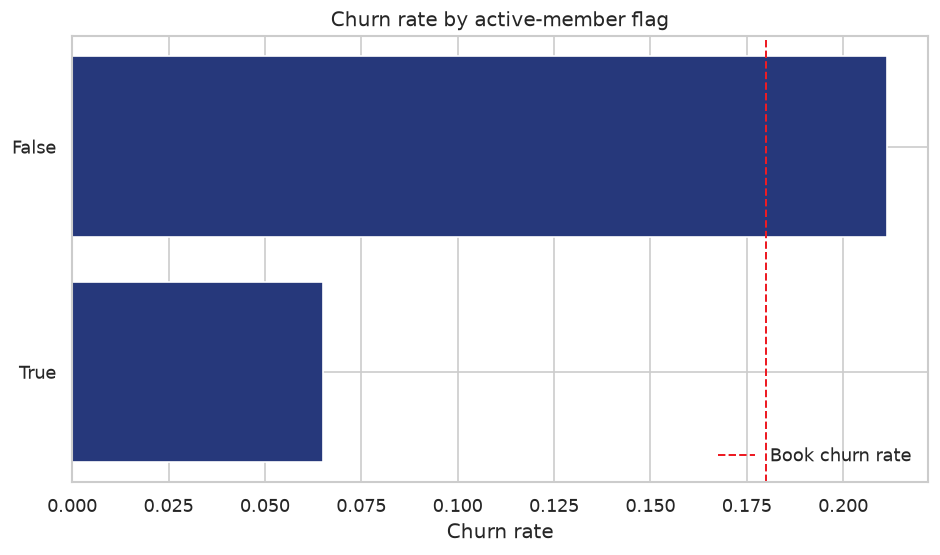

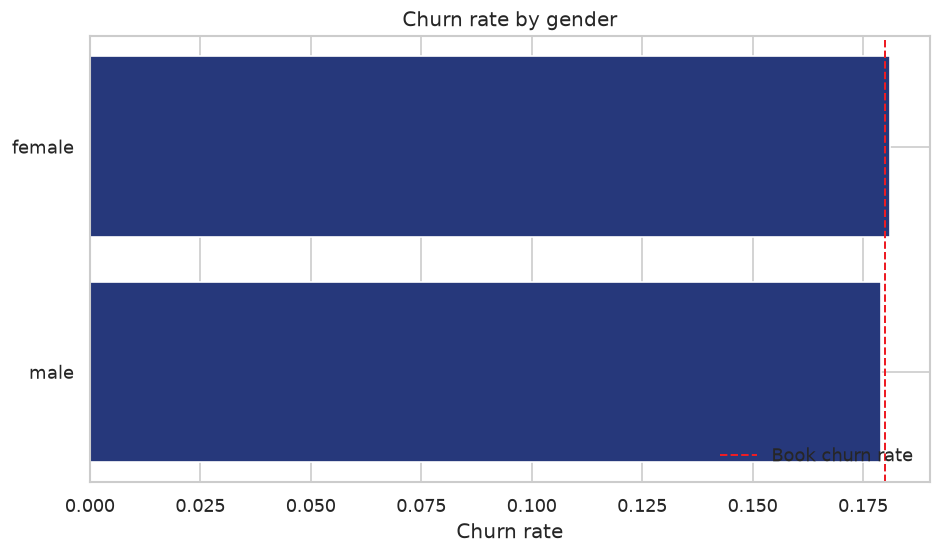

In [4]:
def churn_rate_chart(column, title, filename, figsize=(8, 4.8)):
    rates = raw.groupby(column)["churn"].mean().sort_values()
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(rates.index.astype(str), rates.values, color=NAVY)
    ax.axvline(raw["churn"].mean(), color=RED, ls="--", lw=1.2, label="Book churn rate")
    ax.set_xlabel("Churn rate")
    ax.set_title(title)
    ax.legend(frameon=False, loc="lower right")
    save_show(filename)

churn_rate_chart("occupation", "Churn rate by occupation", "02_churn_by_occupation", (8, 5.2))
churn_rate_chart("origin_province", "Churn rate by province", "03_churn_by_province", (8, 5.2))
churn_rate_chart("customer_segment", "Churn rate by segment", "04_churn_by_segment")
churn_rate_chart("loyalty_level", "Churn rate by loyalty level", "05_churn_by_loyalty")
churn_rate_chart("active_member", "Churn rate by active-member flag", "06_churn_by_activity")
churn_rate_chart("gender", "Churn rate by gender", "07_churn_by_gender")


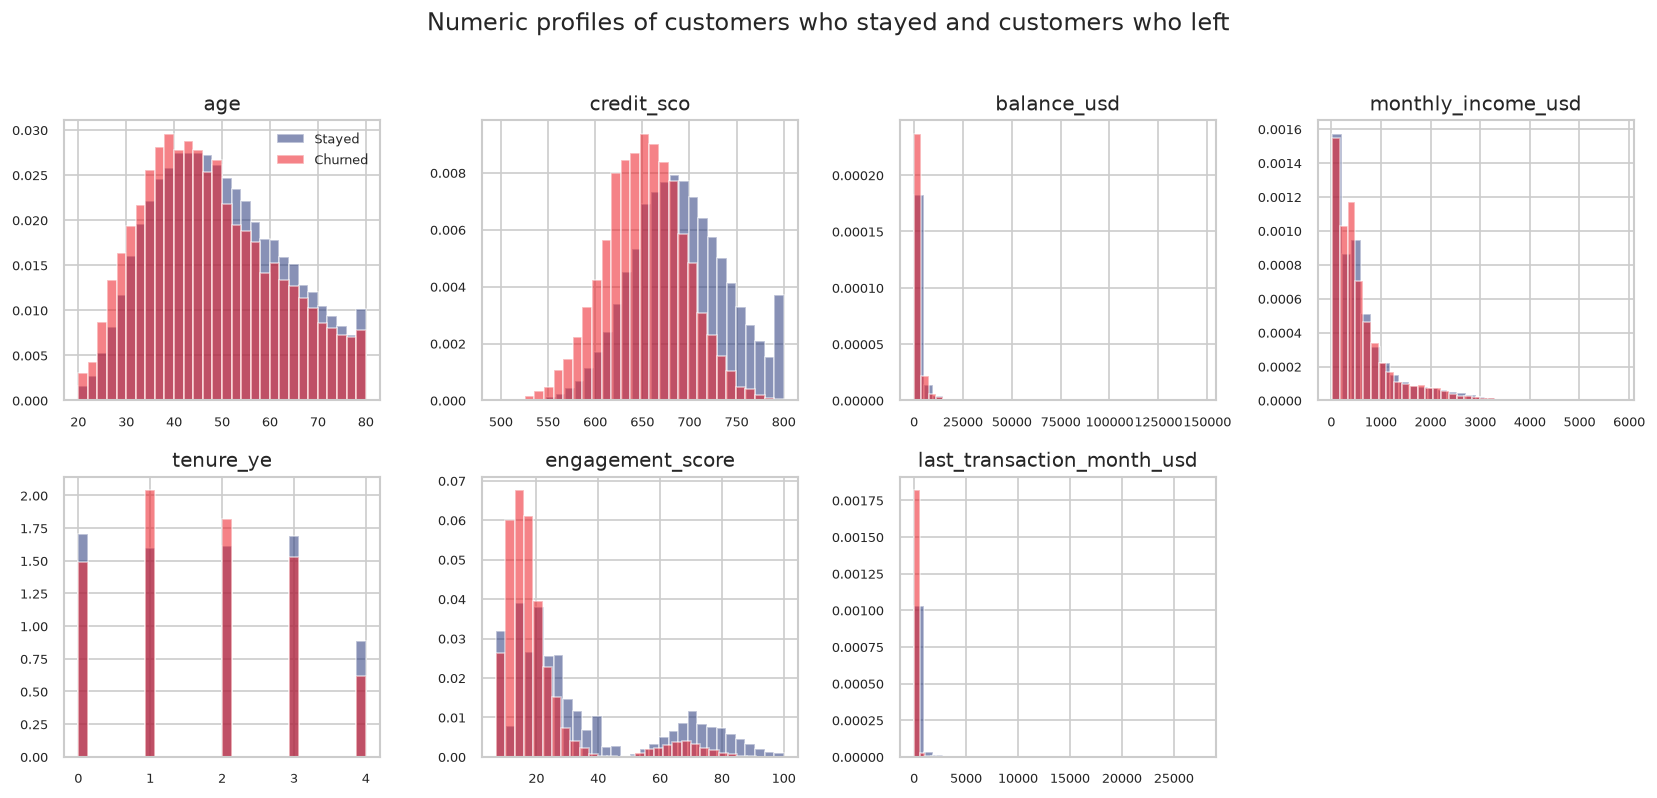

In [5]:
numeric_view = ["age", "credit_sco", "balance_usd", "monthly_income_usd", "tenure_ye", "engagement_score", "last_transaction_month_usd"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
axes = axes.ravel()
for axis, column in zip(axes, numeric_view):
    for label, colour, flag in [("Stayed", NAVY, 0), ("Churned", RED, 1)]:
        subset = raw.loc[raw["churn"] == flag, column]
        axis.hist(subset, bins=30, density=True, alpha=0.55, color=colour, label=label)
    axis.set_title(column)
    axis.tick_params(labelsize=8)
axes[0].legend(frameon=False, fontsize=8)
axes[-1].axis("off")
fig.suptitle("Numeric profiles of customers who stayed and customers who left", y=1.02)
save_show("08_numeric_distributions")


credit_score             -0.287
products_held            -0.267
services_held            -0.262
engagement_score         -0.235
cards_held               -0.119
spend_to_income          -0.110
monthly_spend_usd        -0.079
age                      -0.059
balance_to_income        -0.042
balance_usd              -0.036
tenure_years             -0.028
monthly_income_usd       -0.022
account_age_days         -0.018
days_since_last_active    0.035
Name: churn, dtype: float64


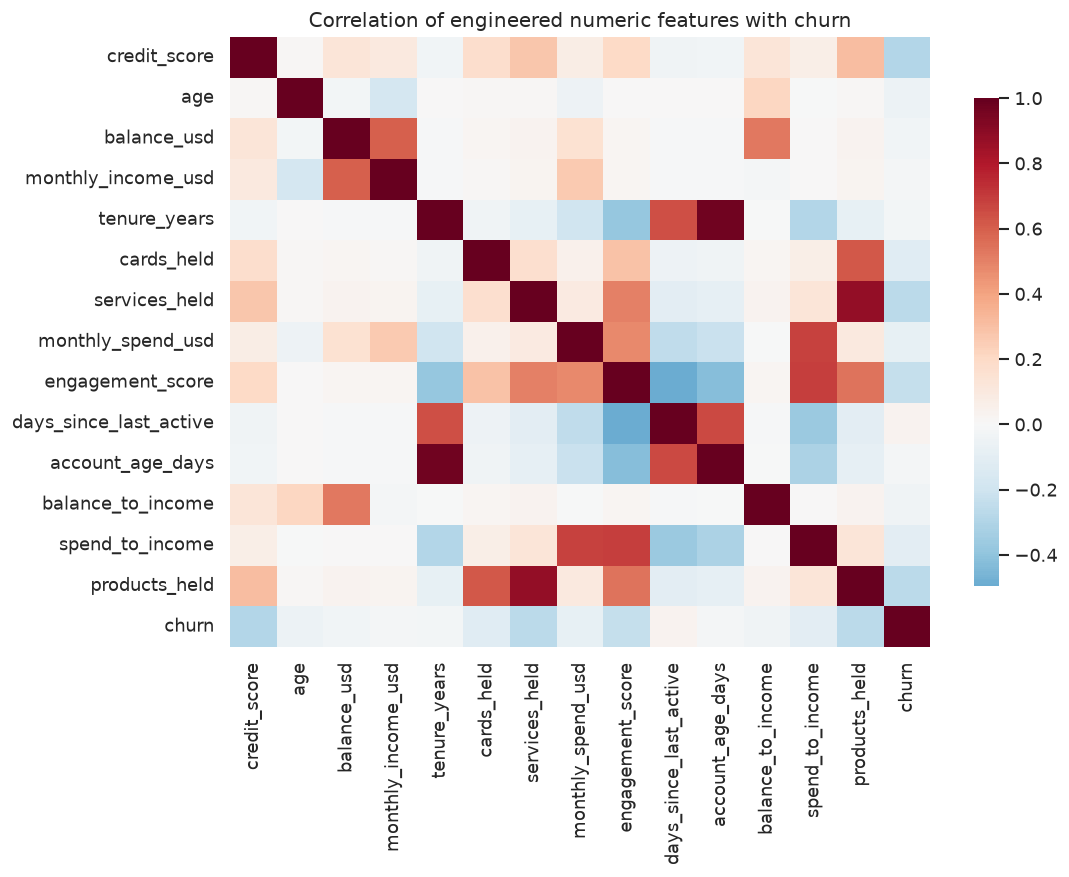

In [6]:
engineered_preview = engineer_features(raw, snapshot=SNAPSHOT_DATE)
corr_frame = engineered_preview[NUMERIC_FEATURES].copy()
corr_frame["churn"] = raw["churn"].values
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr_frame.corr(), cmap="RdBu_r", center=0, ax=ax, square=False, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation of engineered numeric features with churn")
save_show("09_correlation")
print(corr_frame.corr()["churn"].drop("churn").sort_values().round(3))


### Exploratory data analysis

The group charts above show the raw churn rate. The figures below look at the same file from three other angles:

- how the retail book is composed, so a high rate in a tiny group is not mistaken for a large opportunity
- how credit, age, balance, income, engagement, and spend differ between customers who stayed and customers who left
- which combinations of tenure, products, age, engagement, segment, and recent activity sit above the 18% book rate

The dashed line on the rate charts is the book-level churn rate. Counts on the bars are the number of customers in that group.

Median by outcome
churn                       Stayed  Churned
credit_sco                   689.0    653.0
age                           48.0     45.0
balance_usd                  989.4    829.8
monthly_income_usd           434.0    410.8
engagement_score              25.0     16.0
last_transaction_month_usd     0.0      0.0


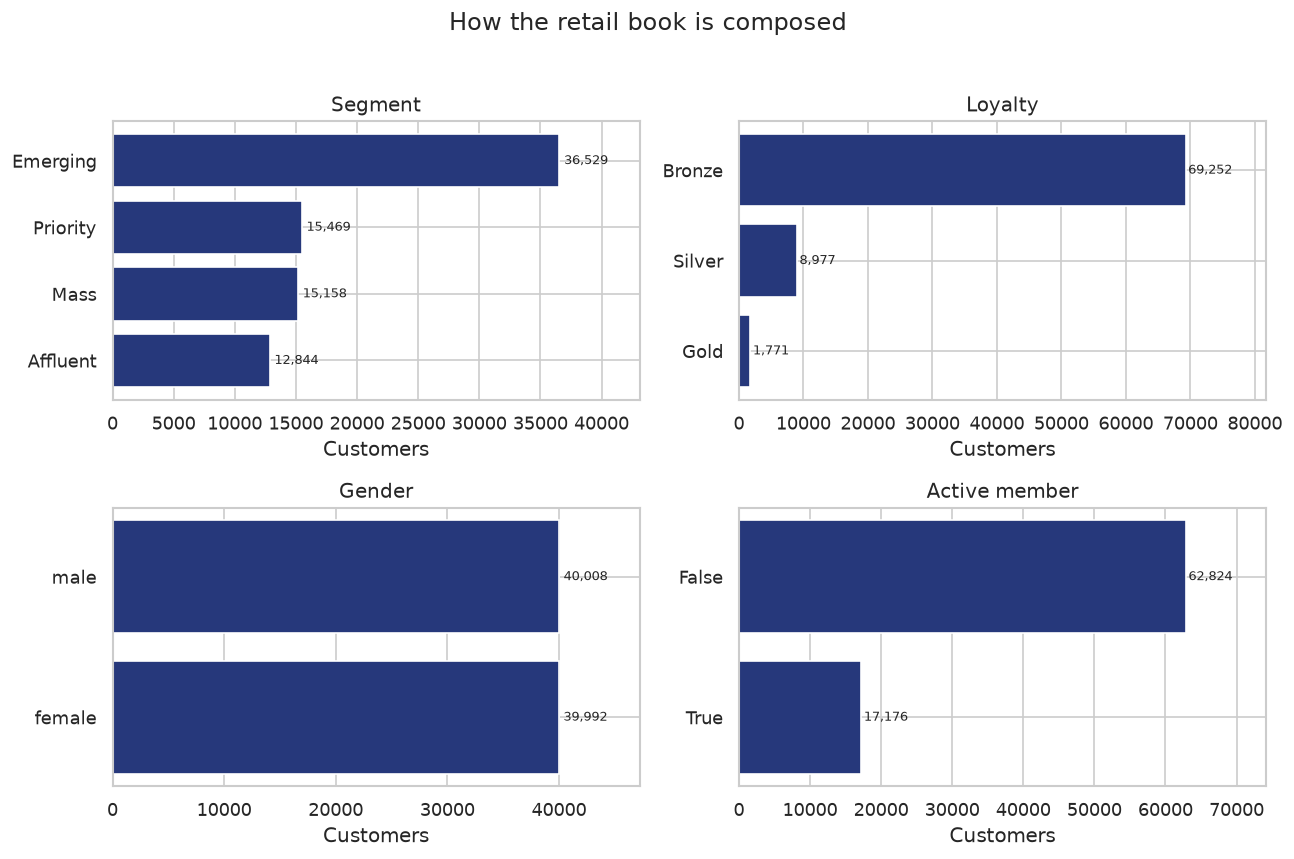

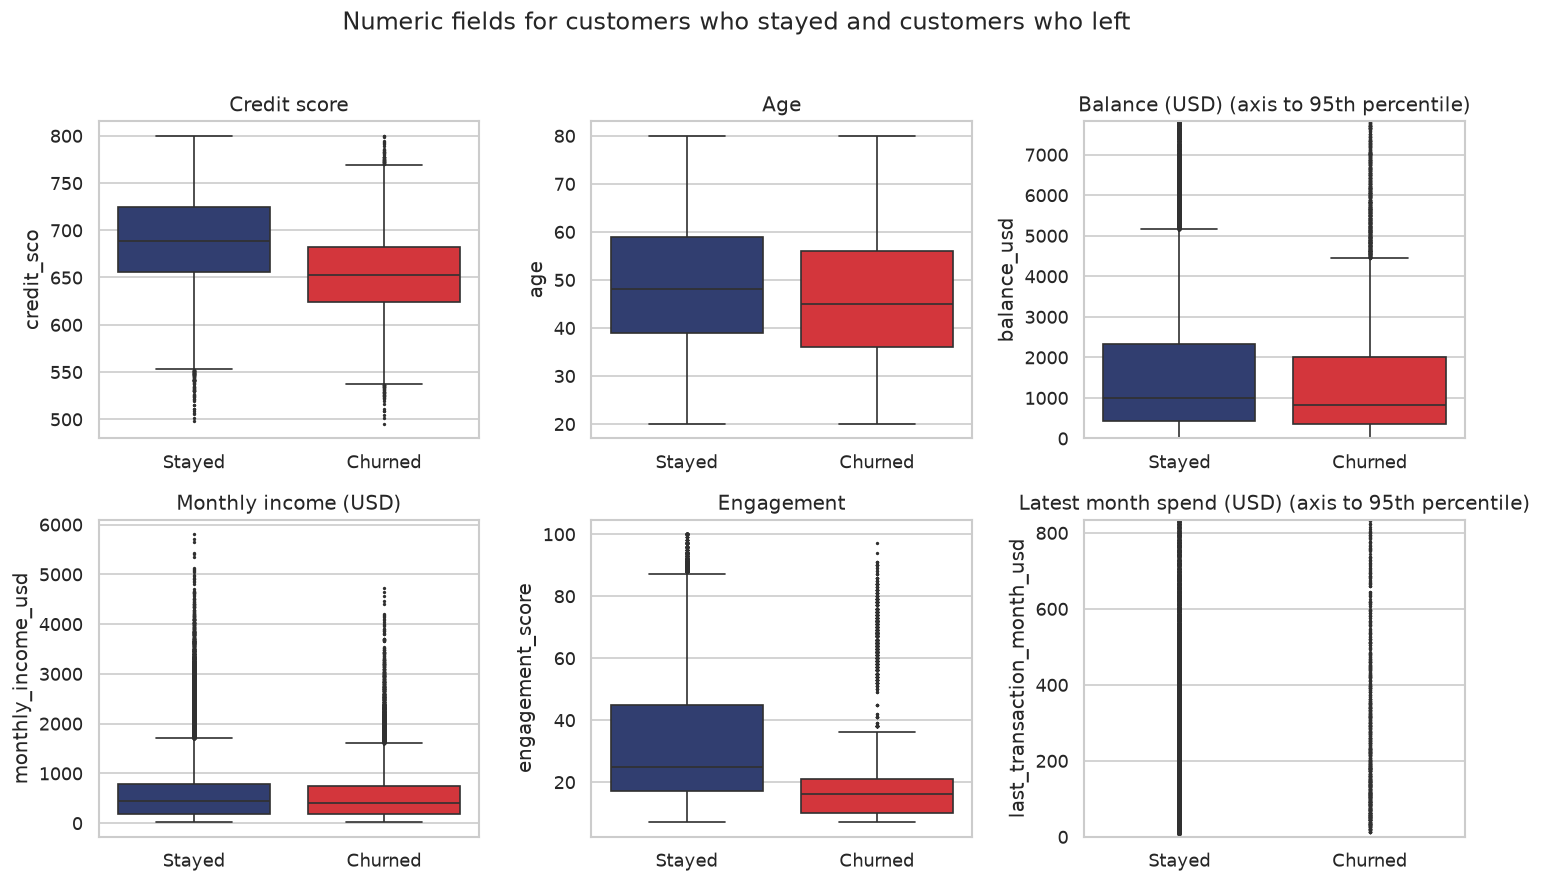

In [11]:
composition = [
    ("customer_segment", "Segment"),
    ("loyalty_level", "Loyalty"),
    ("gender", "Gender"),
    ("active_member", "Active member"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for axis, (column, title) in zip(axes.ravel(), composition):
    counts = raw[column].astype(str).value_counts().sort_values()
    axis.barh(counts.index, counts.values, color=NAVY)
    axis.set_title(title)
    axis.set_xlabel("Customers")
    for bar, value in zip(axis.patches, counts.values):
        axis.text(value + 400, bar.get_y() + bar.get_height() / 2, f"{value:,}", va="center", fontsize=8)
    axis.set_xlim(0, counts.max() * 1.18)
fig.suptitle("How the retail book is composed", y=1.02)
save_show("17_book_composition")

box_columns = [
    ("credit_sco", "Credit score"),
    ("age", "Age"),
    ("balance_usd", "Balance (USD)"),
    ("monthly_income_usd", "Monthly income (USD)"),
    ("engagement_score", "Engagement"),
    ("last_transaction_month_usd", "Latest month spend (USD)"),
]
outcome = raw["churn"].map({0: "Stayed", 1: "Churned"})
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.2))
for axis, (column, title) in zip(axes.ravel(), box_columns):
    sns.boxplot(
        data=raw, x=outcome, y=column, hue=outcome,
        order=["Stayed", "Churned"], palette=[NAVY, RED],
        legend=False, ax=axis, fliersize=1,
    )
    cap = raw[column].quantile(0.95)
    if raw[column].max() > cap * 3:
        axis.set_ylim(0, cap)
        title = title + " (axis to 95th percentile)"
    axis.set_title(title)
    axis.set_xlabel("")
fig.suptitle("Numeric fields for customers who stayed and customers who left", y=1.02)
save_show("18_numeric_boxplots")

compare_cols = [column for column, _ in box_columns]
medians = raw.groupby(outcome, observed=True)[compare_cols].median().T
medians = medians.reindex(columns=["Stayed", "Churned"])
print("Median by outcome")
print(medians.round(1).to_string())

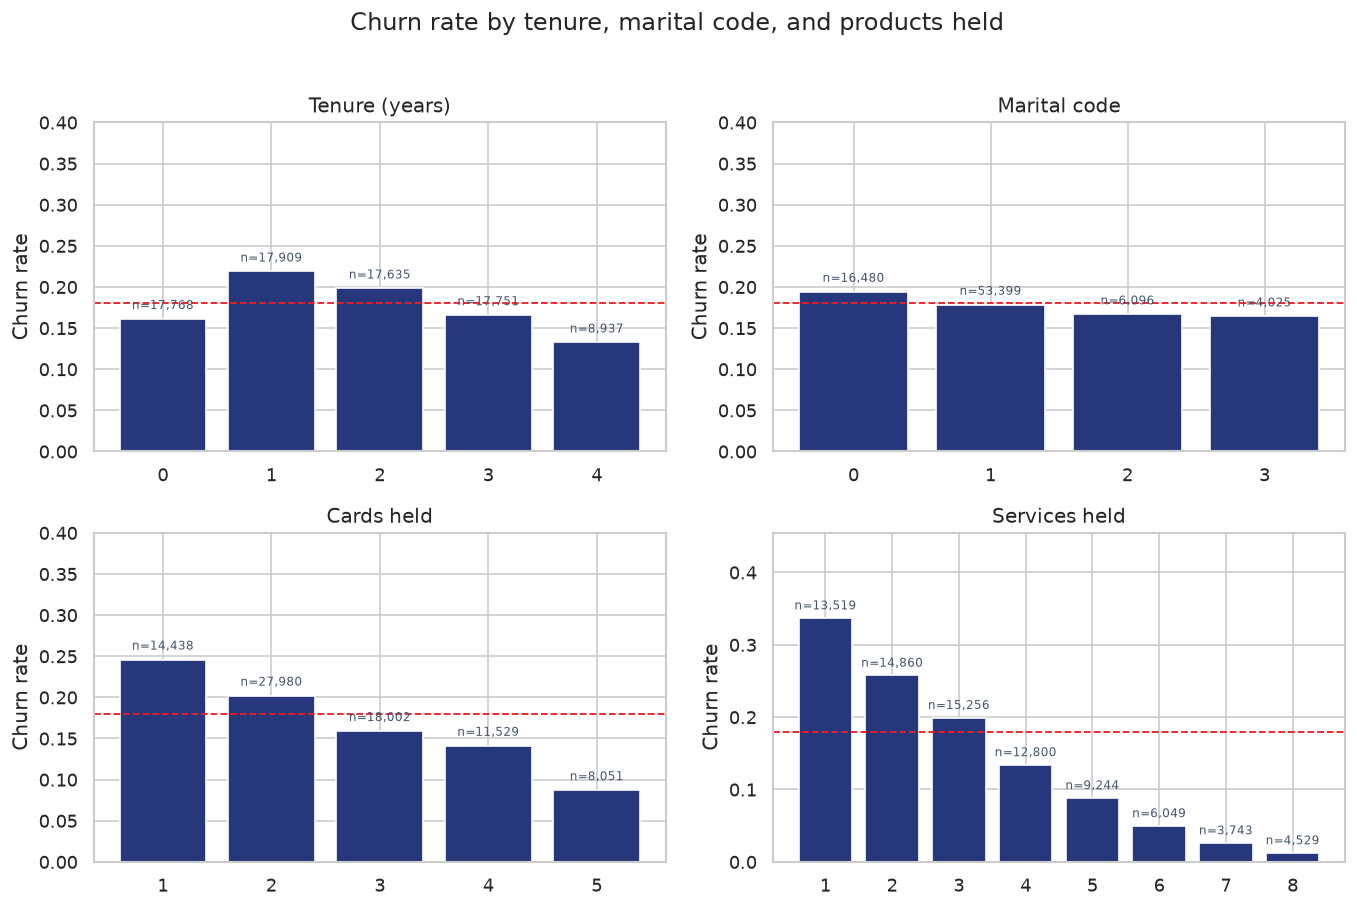

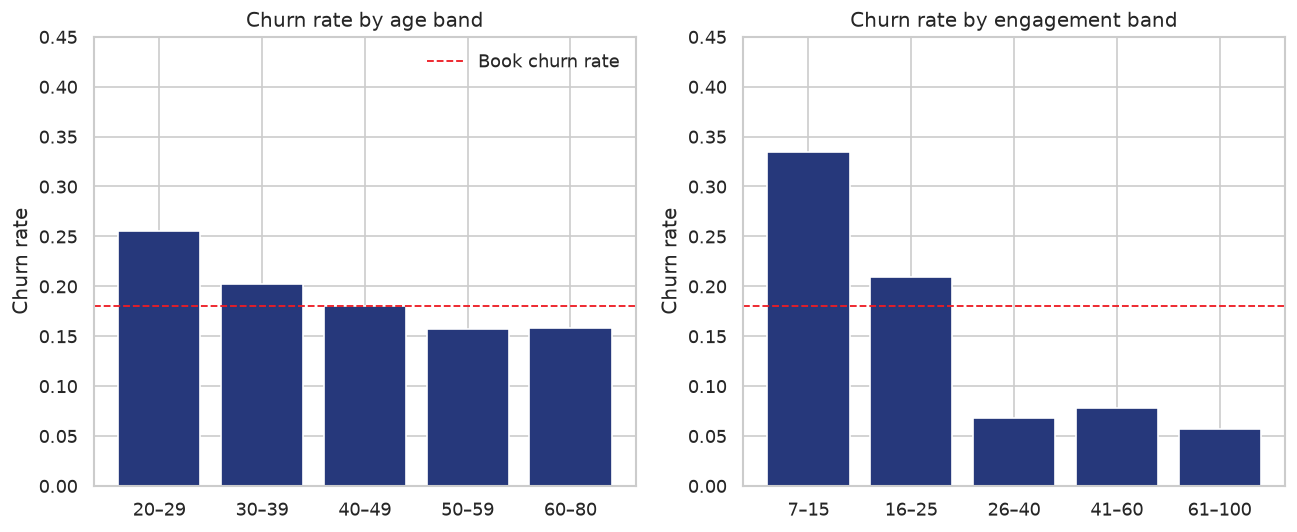

In [12]:
def rate_panel(column, title, axis):
    grouped = raw.groupby(column)["churn"].agg(["mean", "size"]).sort_index()
    axis.bar(grouped.index.astype(str), grouped["mean"], color=NAVY)
    axis.axhline(raw["churn"].mean(), color=RED, ls="--", lw=1.1)
    axis.set_title(title)
    axis.set_ylabel("Churn rate")
    axis.set_ylim(0, max(0.4, grouped["mean"].max() * 1.35))
    for label, mean, size in zip(grouped.index.astype(str), grouped["mean"], grouped["size"]):
        axis.text(label, mean + 0.012, f"n={int(size):,}", ha="center", fontsize=7, color="#475569")

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.4))
rate_panel("tenure_ye", "Tenure (years)", axes[0, 0])
rate_panel("married", "Marital code", axes[0, 1])
rate_panel("nums_card", "Cards held", axes[1, 0])
rate_panel("nums_service", "Services held", axes[1, 1])
fig.suptitle("Churn rate by tenure, marital code, and products held", y=1.02)
save_show("19_churn_by_products")

banded = raw.copy()
banded["age_band"] = pd.cut(
    banded["age"], bins=[19, 29, 39, 49, 59, 81],
    labels=["20–29", "30–39", "40–49", "50–59", "60–80"],
)
banded["engagement_band"] = pd.cut(
    banded["engagement_score"], bins=[0, 15, 25, 40, 60, 101],
    labels=["7–15", "16–25", "26–40", "41–60", "61–100"],
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for axis, column, title in [
    (axes[0], "age_band", "Churn rate by age band"),
    (axes[1], "engagement_band", "Churn rate by engagement band"),
]:
    rates = banded.groupby(column, observed=True)["churn"].mean()
    axis.bar(rates.index.astype(str), rates.values, color=NAVY)
    axis.axhline(raw["churn"].mean(), color=RED, ls="--", lw=1.1, label="Book churn rate")
    axis.set_ylim(0, max(0.45, rates.max() * 1.25))
    axis.set_title(title)
    axis.set_ylabel("Churn rate")
axes[0].legend(frameon=False)
save_show("20_churn_by_bands")

Median days since last activity
outcome
Churned    351.0
Stayed     294.0


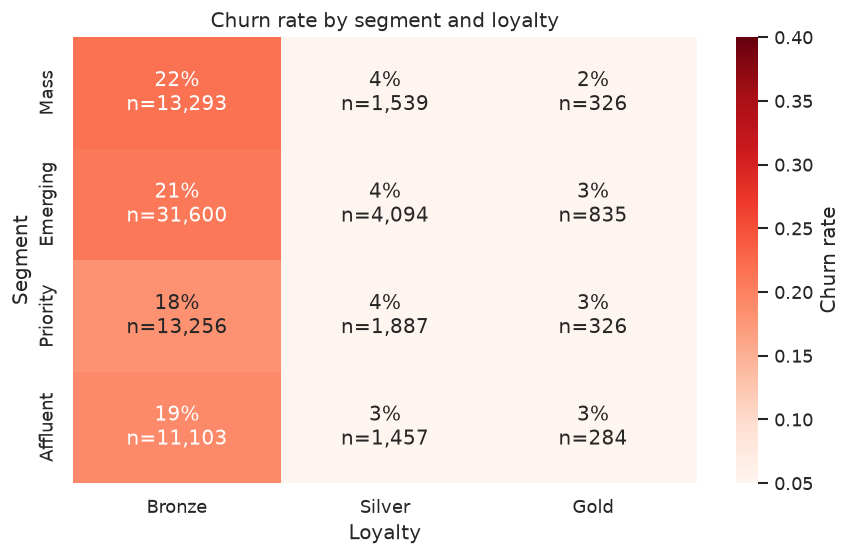

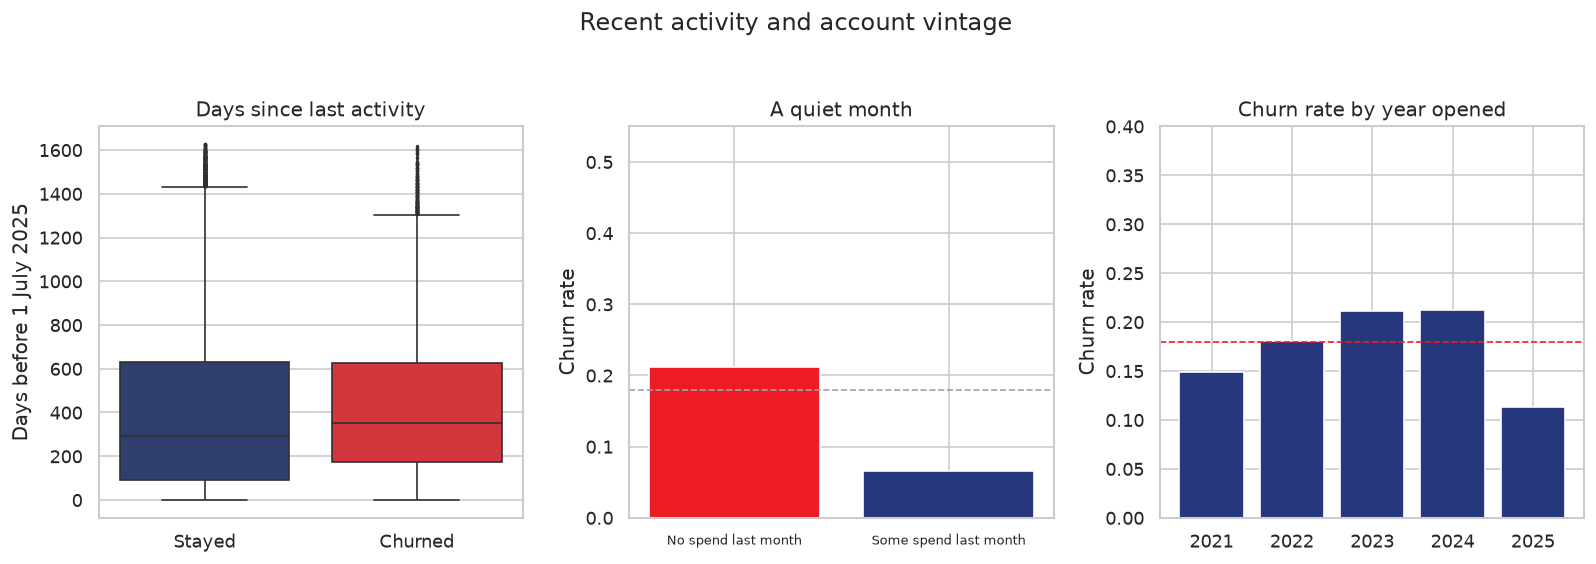

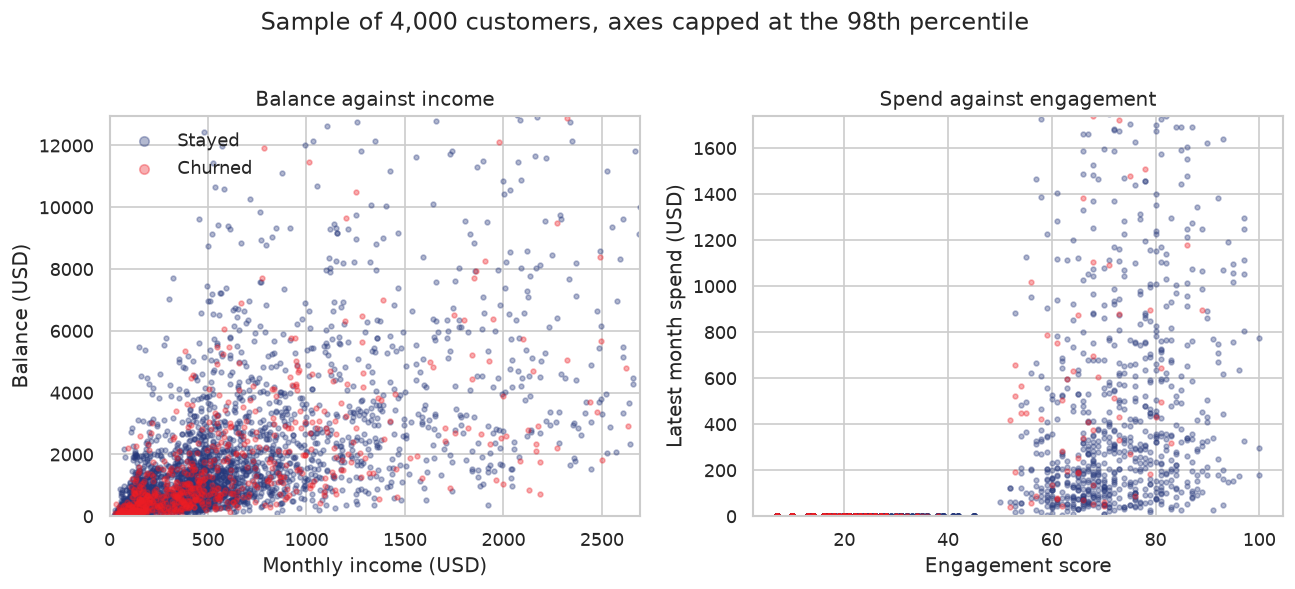

In [13]:
segment_order = ["Mass", "Emerging", "Priority", "Affluent"]
loyalty_order = ["Bronze", "Silver", "Gold"]
heat = raw.pivot_table(index="customer_segment", columns="loyalty_level", values="churn", aggfunc="mean")
heat = heat.reindex(index=segment_order, columns=loyalty_order)
counts = raw.pivot_table(index="customer_segment", columns="loyalty_level", values="churn", aggfunc="size")
counts = counts.reindex(index=segment_order, columns=loyalty_order)
labels = heat.copy().astype(object)
for row in heat.index:
    for column in heat.columns:
        labels.loc[row, column] = f"{heat.loc[row, column]:.0%}\nn={int(counts.loc[row, column]):,}"
fig, ax = plt.subplots(figsize=(7.4, 4.8))
sns.heatmap(heat, annot=labels, fmt="", cmap="Reds", vmin=0.05, vmax=0.4, ax=ax, cbar_kws={"label": "Churn rate"})
ax.set_title("Churn rate by segment and loyalty")
ax.set_xlabel("Loyalty")
ax.set_ylabel("Segment")
save_show("21_segment_loyalty_heatmap")

opened = pd.to_datetime(raw["created_date"], dayfirst=True, errors="coerce")
last_active = pd.to_datetime(raw["last_active_date"], dayfirst=True, errors="coerce")
activity = pd.DataFrame({
    "outcome": raw["churn"].map({0: "Stayed", 1: "Churned"}),
    "days_since_last_active": (SNAPSHOT_DATE - last_active).dt.days.clip(lower=0),
    "opened_year": opened.dt.year,
    "spend_pattern": np.where(raw["last_transaction_month_usd"] <= 0, "No spend last month", "Some spend last month"),
})
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5))
sns.boxplot(
    data=activity, x="outcome", y="days_since_last_active", hue="outcome",
    order=["Stayed", "Churned"], palette=[NAVY, RED], legend=False, ax=axes[0], fliersize=1,
)
axes[0].set_title("Days since last activity")
axes[0].set_xlabel("")
axes[0].set_ylabel("Days before 1 July 2025")
spend_rate = activity.groupby("spend_pattern")["outcome"].apply(lambda series: (series == "Churned").mean())
spend_rate = spend_rate.reindex(["No spend last month", "Some spend last month"])
axes[1].bar(spend_rate.index, spend_rate.values, color=[RED, NAVY])
axes[1].axhline(raw["churn"].mean(), color="#98a2b3", ls="--", lw=1)
axes[1].set_ylim(0, 0.55)
axes[1].set_ylabel("Churn rate")
axes[1].set_title("A quiet month")
axes[1].tick_params(axis="x", labelsize=8)
year_rate = activity.groupby("opened_year")["outcome"].apply(lambda series: (series == "Churned").mean()).sort_index()
axes[2].bar(year_rate.index.astype(str), year_rate.values, color=NAVY)
axes[2].axhline(raw["churn"].mean(), color=RED, ls="--", lw=1)
axes[2].set_ylim(0, max(0.4, year_rate.max() * 1.3))
axes[2].set_title("Churn rate by year opened")
axes[2].set_ylabel("Churn rate")
fig.suptitle("Recent activity and account vintage", y=1.04)
save_show("22_activity_patterns")
print("Median days since last activity")
print(activity.groupby("outcome")["days_since_last_active"].median().round(0).to_string())

sample = raw.sample(4000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for flag, label, colour in [(0, "Stayed", NAVY), (1, "Churned", RED)]:
    part = sample[sample["churn"] == flag]
    axes[0].scatter(part["monthly_income_usd"], part["balance_usd"], s=8, alpha=0.35, c=colour, label=label)
    axes[1].scatter(part["engagement_score"], part["last_transaction_month_usd"], s=8, alpha=0.35, c=colour, label=label)
axes[0].set_xlim(0, raw["monthly_income_usd"].quantile(0.98))
axes[0].set_ylim(0, raw["balance_usd"].quantile(0.98))
axes[1].set_ylim(0, raw["last_transaction_month_usd"].quantile(0.98))
axes[0].set_xlabel("Monthly income (USD)")
axes[0].set_ylabel("Balance (USD)")
axes[0].set_title("Balance against income")
axes[1].set_xlabel("Engagement score")
axes[1].set_ylabel("Latest month spend (USD)")
axes[1].set_title("Spend against engagement")
axes[0].legend(frameon=False, markerscale=2)
fig.suptitle("Sample of 4,000 customers, axes capped at the 98th percentile", y=1.02)
save_show("23_relationships")

### What the exploration shows

The book is broad, but a few groups carry more of the exits:

- **Low product depth.** Customers with one service churn at about 34%. The rate falls steadily as services increase, and it is about 1% among customers with eight services. Cards show the same direction, from about 25% with one card to about 9% with five.
- **Low engagement and a quiet month.** The 7–15 engagement band sits well above the 18% book rate. Median engagement is 16 for customers who left and 25 for those who stayed. About 92% of churners recorded no spend in the latest month, against about 76% of customers who stayed. Where there was some spend, the churn rate is about 7%.
- **Bronze loyalty.** Silver and Gold sit near 2–4% in every segment. Bronze, which is most of the book, sits near the book rate or a little above it. A high rate in Gold would have been a small group; the Bronze pattern is a large one.
- **Early relationship.** Tenure of one year is the highest tenure band, about 22%. Customers aged 20–29 are also above the book rate. Customers who left were last active a median of 351 days before the 1 July 2025 snapshot, against 294 days for those who stayed.

Credit score, age, balance, and income overlap heavily. Their medians differ, but not enough to separate the classes on their own. Marital code barely moves the rate. The later model has to use these fields together rather than rely on one split.

## 3. Data preparation

The model uses behaviour and profile fields a member of staff can recognise. Four exclusions are deliberate:

- `id` and `full_name` identify a person. They are not predictors.
- `digital_behavior` is checked below. If it is a copy of `active_member`, keeping both would double-count one fact.
- `risk_score`, `risk_segment`, and `cluster_group` are existing analytical outputs. Training on them would copy another score rather than learn from customer behaviour.

Activity is measured against 1 July 2025, the latest date in the file. From the raw dates the notebook builds days since last activity, account age in days, balance-to-income, spend-to-income, and total products held. Marital status stays as the codes 0, 1, 2, and 3 because the file has no legend for them.

Class imbalance is handled inside the estimators: balanced class weights for logistic regression, the tree, and the forest, and `scale_pos_weight` for XGBoost. The holdout is stratified so the 18% churn rate is preserved in train, validation, and test.


Share of rows where digital_behavior repeats active_member: 100.0%
Model columns: 21
   credit_score  age  balance_usd  monthly_income_usd  tenure_years  cards_held  services_held  monthly_spend_usd  engagement_score  days_since_last_active  account_age_days  balance_to_income  spend_to_income  products_held  gender                       occupation   origin_province marital_status active_member customer_segment loyalty_level
0           725   55     11741.67             4094.92             0           4              8            3080.97                90                      89               124           2.866675         0.752205             12    male                Manager/Executive  Mashonaland East              2           yes         Priority        Bronze
1           689   45       801.16              414.64             3           3              2             269.98                63                      48              1433           1.927533         0.649552              5   

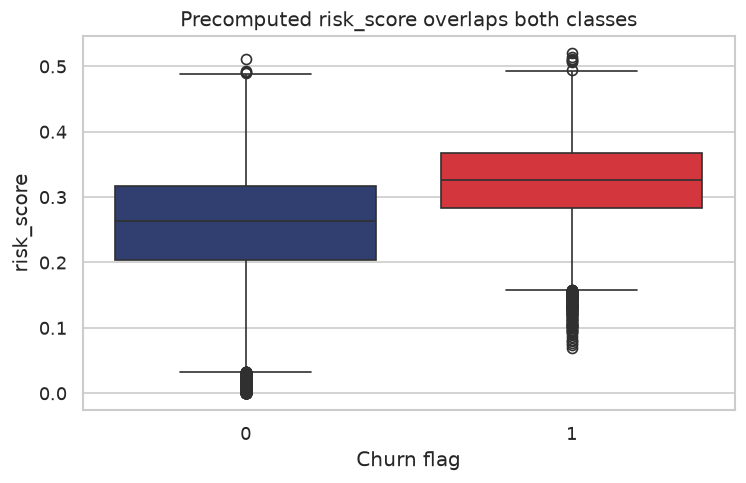

In [7]:
active_text = raw["active_member"].astype(str).str.lower()
digital = raw["digital_behavior"].astype(str).str.lower()
same_signal = ((digital.eq("mobile") & active_text.isin(["true", "yes", "1"])) | (digital.eq("offline") & active_text.isin(["false", "no", "0"]))).mean()
print(f"Share of rows where digital_behavior repeats active_member: {same_signal:.1%}")

fig, ax = plt.subplots(figsize=(6.4, 4.2))
sns.boxplot(data=raw, x="churn", y="risk_score", hue="churn", ax=ax, palette=[NAVY, RED], legend=False)
ax.set_title("Precomputed risk_score overlaps both classes")
ax.set_xlabel("Churn flag")
ax.set_ylabel("risk_score")
save_show("10_risk_score_overlap")

features = engineer_features(raw, snapshot=SNAPSHOT_DATE)
print("Model columns:", len(features.columns))
print(features.head(3).to_string())
print("Missing values after engineering:", int(features.isna().sum().sum()))


In [8]:
y = raw["churn"].astype(int)
ids = raw["id"].astype(str)
names = raw["full_name"].astype(str)

X_trainval, X_test, y_trainval, y_test, id_trainval, id_test, name_trainval, name_test, raw_trainval, raw_test = train_test_split(
    features, y, ids, names, raw, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42
)

print(f"Train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,}")
print("Churn rate train/val/test:", round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"XGBoost scale_pos_weight (stayed/churned in train): {scale_pos_weight:.2f}")


Train 48,000 | validation 16,000 | test 16,000
Churn rate train/val/test: 0.18 0.18 0.18
XGBoost scale_pos_weight (stayed/churned in train): 4.56


## 4. Modelling

Each algorithm sits in the same preprocessing pipeline. Numeric fields are median-imputed and scaled. Categories are one-hot encoded, and an unseen category at scoring time is ignored rather than rejected.

Hyperparameters are intentionally modest. Chapter 1 notes that the academic timetable does not allow an open-ended search, so depth and leaf size are set to limit memorising the training book.

| Model | Role | Imbalance handling |
| --- | --- | --- |
| Logistic regression | Linear baseline | `class_weight="balanced"` |
| Decision tree | Readable single tree | `class_weight="balanced"`, depth 6 |
| Random forest | Bagged trees | `balanced_subsample` |
| XGBoost | Boosted trees | `scale_pos_weight` |

Selection uses validation F1. The test set is scored once for the comparison table and is not used to choose the algorithm.


In [9]:
def make_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])

def make_models(pos_weight):
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=42),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=15,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1,
        ),
        "XGBoost": XGBClassifier(
            n_estimators=160, max_depth=4, learning_rate=0.08,
            subsample=0.85, colsample_bytree=0.85,
            scale_pos_weight=pos_weight, objective="binary:logistic",
            eval_metric="logloss", random_state=42, n_jobs=-1, tree_method="hist",
        ),
    }

def build_pipeline(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])

METRIC_NAMES = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def metric_row(y_true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, predicted),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
    }

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {name: name for name in METRIC_NAMES}
fitted = {}
rows = []

for name, estimator in make_models(scale_pos_weight).items():
    pipeline = build_pipeline(estimator)
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    pipeline.fit(X_train, y_train)
    val_probability = pipeline.predict_proba(X_val)[:, 1]
    test_probability = pipeline.predict_proba(X_test)[:, 1]
    val_metrics = metric_row(y_val, val_probability)
    test_metrics = metric_row(y_test, test_probability)
    fitted[name] = {"pipeline": pipeline, "val": val_metrics, "test": test_metrics, "test_probability": test_probability}
    rows.append({
        "model": name,
        "val_f1": val_metrics["f1"],
        "cv_f1": cv_scores["test_f1"].mean(),
        "cv_roc_auc": cv_scores["test_roc_auc"].mean(),
        **{f"test_{key}": test_metrics[key] for key in list(METRIC_NAMES) + ["pr_auc"]},
    })
    print(f"{name}: validation F1 {val_metrics['f1']:.3f} | test F1 {test_metrics['f1']:.3f} | test ROC-AUC {test_metrics['roc_auc']:.3f}")

comparison = pd.DataFrame(rows).sort_values(["val_f1", "cv_roc_auc"], ascending=False)
selected_name = comparison.iloc[0]["model"]
print("Selected on validation F1:", selected_name)
print(comparison.round(3).to_string(index=False))


Logistic Regression: validation F1 0.468 | test F1 0.469 | test ROC-AUC 0.792
Decision Tree: validation F1 0.456 | test F1 0.459 | test ROC-AUC 0.774
Random Forest: validation F1 0.470 | test F1 0.471 | test ROC-AUC 0.785
XGBoost: validation F1 0.466 | test F1 0.463 | test ROC-AUC 0.790
Selected on validation F1: Random Forest
              model  val_f1  cv_f1  cv_roc_auc  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  test_pr_auc
      Random Forest   0.470  0.469       0.785          0.716           0.354        0.704    0.471         0.785        0.425
Logistic Regression   0.468  0.470       0.793          0.694           0.341        0.750    0.469         0.792        0.441
            XGBoost   0.466  0.466       0.790          0.681           0.332        0.764    0.463         0.790        0.435
      Decision Tree   0.456  0.450       0.777          0.682           0.331        0.751    0.459         0.774        0.392


## 5. Evaluation

The bars compare the five metrics named in Research Question 2 on the same unseen 20% of customers, using a 0.5 probability cut. Accuracy is the easiest number to over-read: a model that called everyone "stayed" would already be about 82% accurate. Precision, recall, F1, and ROC-AUC show whether the churners are actually being found.


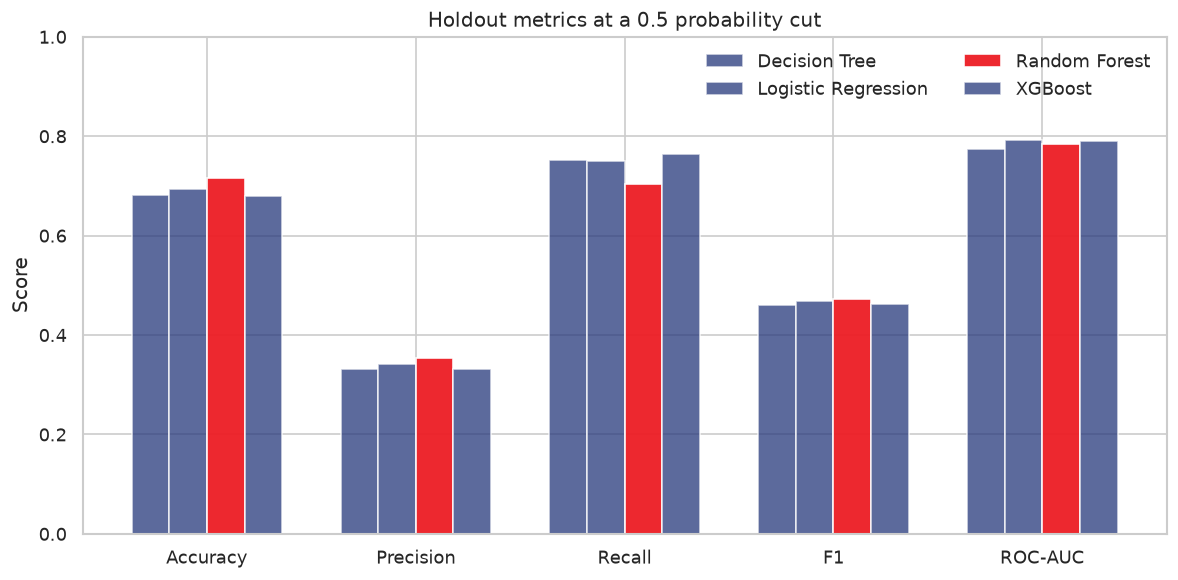

In [10]:
plot_frame = comparison.sort_values("model")
metrics_for_plot = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
x = np.arange(len(labels))
width = 0.18
fig, ax = plt.subplots(figsize=(10, 5))
for index, (_, row) in enumerate(plot_frame.iterrows()):
    offset = (index - (len(plot_frame) - 1) / 2) * width
    colour = RED if row["model"] == selected_name else NAVY
    ax.bar(x + offset, [row[metric] for metric in metrics_for_plot], width=width, label=row["model"], color=colour, alpha=0.95 if row["model"] == selected_name else 0.75)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Holdout metrics at a 0.5 probability cut")
ax.legend(frameon=False, ncol=2)
save_show("11_model_comparison")


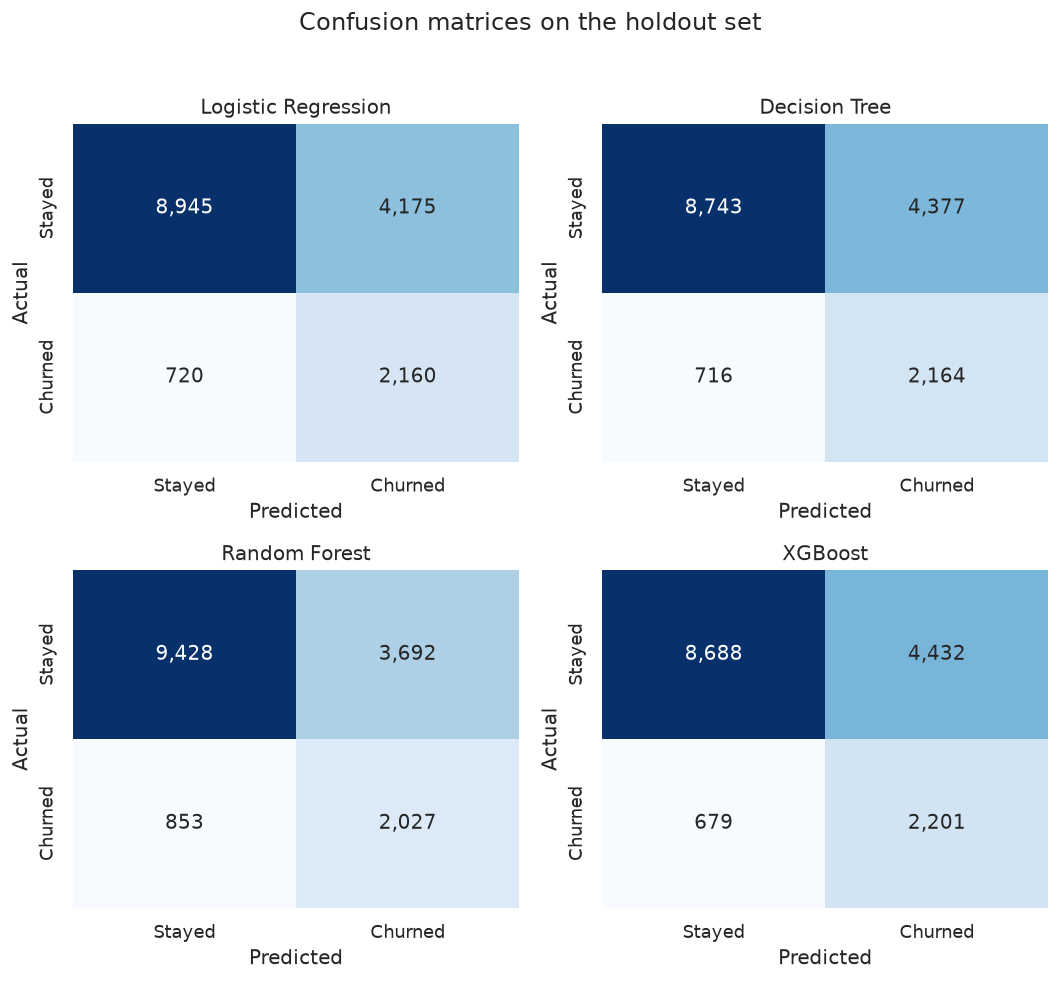

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for axis, (name, bundle) in zip(axes.ravel(), fitted.items()):
    predicted = (bundle["test_probability"] >= 0.5).astype(int)
    matrix = confusion_matrix(y_test, predicted)
    sns.heatmap(matrix, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    axis.set_title(name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
fig.suptitle("Confusion matrices on the holdout set", y=1.02)
save_show("12_confusion_matrices")


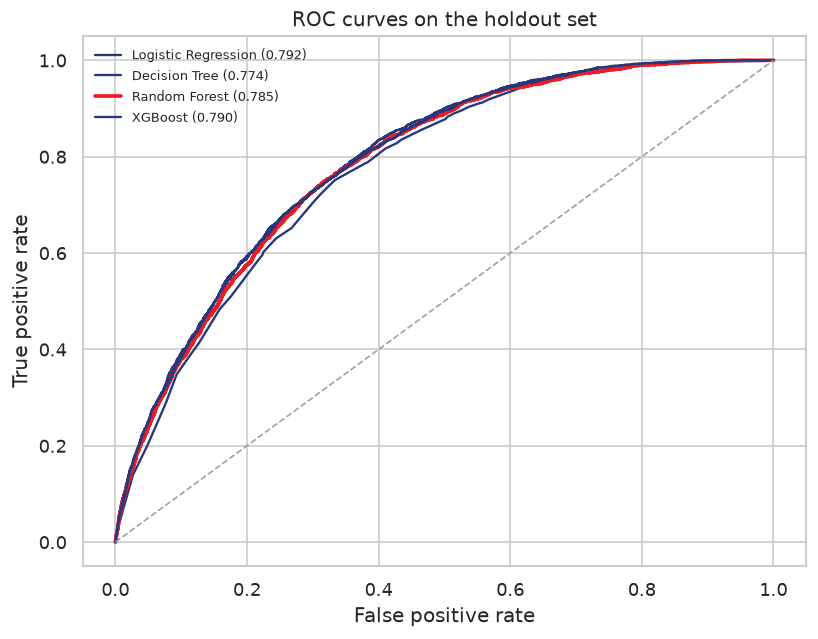

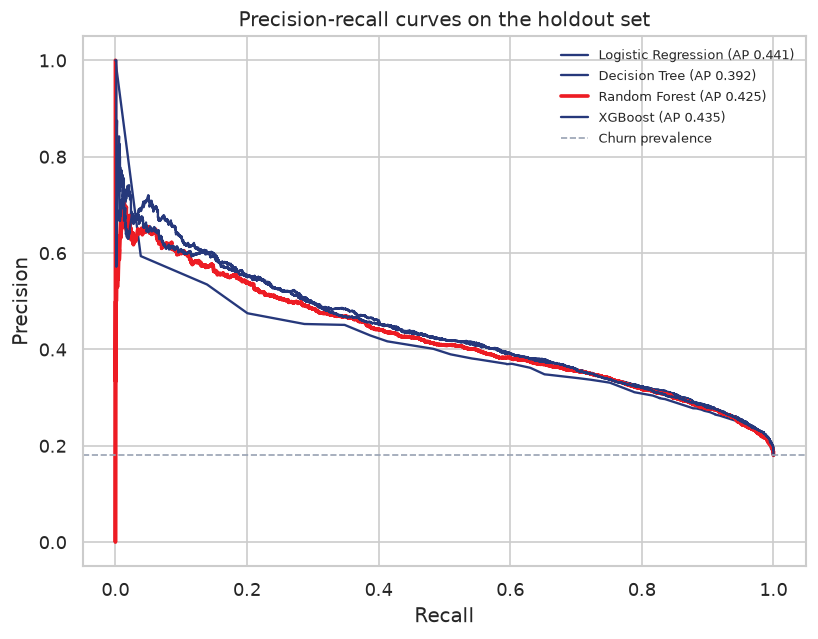

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for name, bundle in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, bundle["test_probability"])
    auc = bundle["test"]["roc_auc"]
    ax.plot(fpr, tpr, lw=2.2 if name == selected_name else 1.4, color=RED if name == selected_name else NAVY,
            label=f"{name} ({auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#98a2b3", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the holdout set")
ax.legend(frameon=False, fontsize=8)
save_show("13_roc_curves")

fig, ax = plt.subplots(figsize=(7, 5.5))
for name, bundle in fitted.items():
    precision, recall, _ = precision_recall_curve(y_test, bundle["test_probability"])
    ax.plot(recall, precision, lw=2.2 if name == selected_name else 1.4, color=RED if name == selected_name else NAVY,
            label=f"{name} (AP {bundle['test']['pr_auc']:.3f})")
ax.axhline(y_test.mean(), color="#98a2b3", ls="--", lw=1, label="Churn prevalence")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves on the holdout set")
ax.legend(frameon=False, fontsize=8)
save_show("14_precision_recall")


## 6. From a probability to a worklist

The winning pipeline is calibrated on the validation customers so a score near 0.18 matches the book churn rate, rather than only ranking customers. Because calibrated scores rarely climb past 0.60, the worklist does not wait for an 80% chance. The five statuses use fixed cuts on that calibrated chance:

- under 15%: Retained, below the 18% book rate
- 15% to under 28%: At-Risk Low
- 28% to under 40%: At-Risk Medium
- 40% to under 50%: At-Risk High
- 50% and above: Churned, about three times the book rate

"Churned" on the worklist means the model puts the chance of leaving at 50% or more. It is not a record that the account has already been closed. A separate F1-maximising cut is reported for the binary screen, but the staff tool sorts people with these five bands.


In [13]:
base = fitted[selected_name]["pipeline"]
calibrated = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid")
calibrated.fit(X_val, y_val)

val_cal = calibrated.predict_proba(X_val)[:, 1]
test_cal = calibrated.predict_proba(X_test)[:, 1]
uncalibrated_test = metric_row(y_test, fitted[selected_name]["test_probability"])

best_threshold = 0.5
best_f1 = -1
for cut in np.linspace(0.2, 0.8, 61):
    score = f1_score(y_val, (val_cal >= cut).astype(int), zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = float(cut)

calibrated_test = metric_row(y_test, test_cal, threshold=best_threshold)
print(f"Validation F1 threshold: {best_threshold:.2f}")
print("Uncalibrated test metrics at 0.5:")
print(pd.Series(uncalibrated_test).round(3))
print("Calibrated test metrics at the validation threshold:")
print(pd.Series(calibrated_test).round(3))

use_calibrated = calibrated_test["f1"] + 0.01 >= uncalibrated_test["f1"]
deployed = calibrated if use_calibrated else base
deployed_probability = test_cal if use_calibrated else fitted[selected_name]["test_probability"]
deployed_threshold = 0.40 if use_calibrated else 0.5
print("Priority band starts at", deployed_threshold, "| F1-maximising cut was", round(best_threshold, 2))
print("Deployed:", "calibrated " + selected_name if use_calibrated else selected_name)


Validation F1 threshold: 0.22
Uncalibrated test metrics at 0.5:
accuracy     0.716
precision    0.354
recall       0.704
f1           0.471
roc_auc      0.785
pr_auc       0.425
dtype: float64
Calibrated test metrics at the validation threshold:
accuracy     0.725
precision    0.360
recall       0.681
f1           0.471
roc_auc      0.785
pr_auc       0.425
dtype: float64
Priority band starts at 0.4 | F1-maximising cut was 0.22
Deployed: calibrated Random Forest


credit_score              0.0769
engagement_score          0.0126
services_held             0.0107
loyalty_level             0.0073
products_held             0.0047
account_age_days          0.0034
age                       0.0017
tenure_years              0.0012
active_member             0.0007
customer_segment          0.0003
origin_province           0.0001
gender                   -0.0002
marital_status           -0.0004
monthly_spend_usd        -0.0005
balance_to_income        -0.0005
spend_to_income          -0.0006
balance_usd              -0.0006
monthly_income_usd       -0.0010
cards_held               -0.0010
occupation               -0.0012
days_since_last_active   -0.0017
dtype: float64


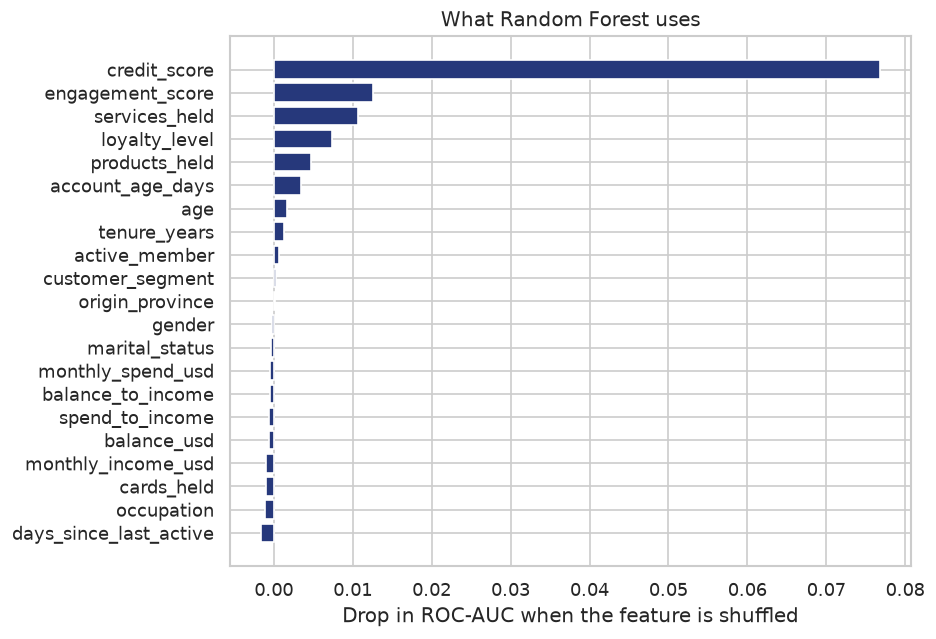

In [14]:
sample_index = X_test.sample(2500, random_state=42).index
importance = permutation_importance(
    deployed, X_test.loc[sample_index], y_test.loc[sample_index],
    n_repeats=4, random_state=42, scoring="roc_auc", n_jobs=-1,
)
grouped = pd.Series(importance.importances_mean, index=MODEL_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(grouped.index, grouped.values, color=NAVY)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"What {selected_name} uses")
save_show("15_feature_importance")
print(grouped.sort_values(ascending=False).round(4))


                 mean  size
band                       
Retained        0.066  8725
At-Risk Low     0.218  3081
At-Risk Medium  0.310  2082
At-Risk High    0.424  1516
Churned         0.582   596


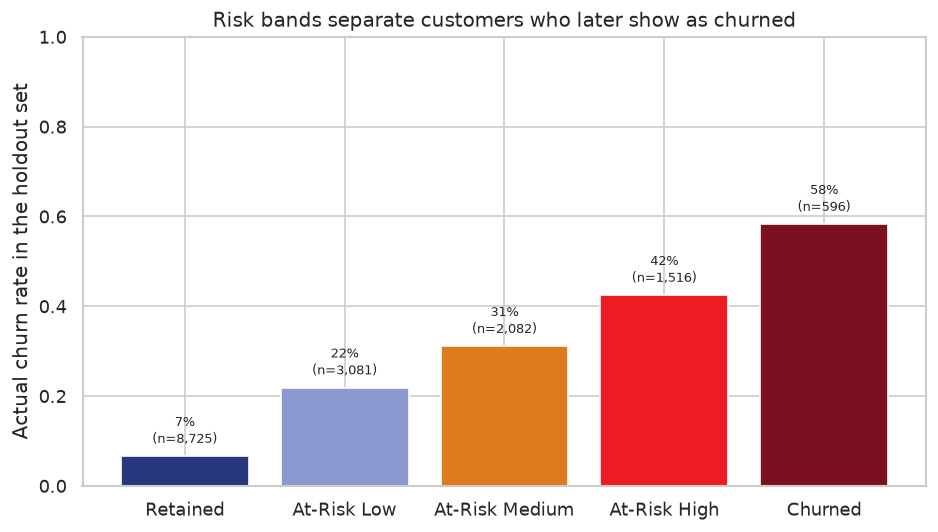

In [15]:
band = pd.Series(deployed_probability, index=X_test.index).map(status_from_probability)
band_order = ["Retained", "At-Risk Low", "At-Risk Medium", "At-Risk High", "Churned"]
summary = pd.DataFrame({"band": band, "churn": y_test.values})
rate = summary.groupby("band")["churn"].agg(["mean", "size"]).reindex(band_order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(rate.index.astype(str), rate["mean"], color=[NAVY, "#8B99D0", "#E07A1F", RED, "#7A1020"])
ax.set_ylabel("Actual churn rate in the holdout set")
ax.set_title("Risk bands separate customers who later show as churned")
ax.set_ylim(0, 1)
for label, value, size in zip(rate.index, rate["mean"], rate["size"]):
    ax.text(label, value + 0.03, f"{value:.0%}\n(n={int(size):,})", ha="center", fontsize=8)
save_show("16_risk_bands")
print(rate.round(3))


## 7. Save the model for the staff tool

The dumped file contains the fitted pipeline, the snapshot date, the decision threshold, two example customers for the form, and the typical engagement score used in the plain-language cues. The React screen reads the model card written next to it. Scoring a new row uses the same `engineer_features` function as this notebook, so the API cannot drift from the study.


In [16]:
LABELS = {
    "credit_score": "Credit score",
    "age": "Age",
    "balance_usd": "Balance (USD)",
    "monthly_income_usd": "Monthly income",
    "tenure_years": "Tenure",
    "cards_held": "Cards held",
    "services_held": "Services held",
    "monthly_spend_usd": "Latest month spend",
    "engagement_score": "Engagement",
    "days_since_last_active": "Days since last activity",
    "account_age_days": "Account age",
    "balance_to_income": "Balance to income",
    "spend_to_income": "Spend to income",
    "products_held": "Products held",
    "gender": "Gender",
    "occupation": "Occupation",
    "origin_province": "Province",
    "marital_status": "Marital code",
    "active_member": "Active member",
    "customer_segment": "Segment",
    "loyalty_level": "Loyalty",
}

ranked_importance = grouped.sort_values(ascending=False)
feature_importance = [
    {"feature": feature, "label": LABELS.get(feature, feature), "importance": round(float(value), 4)}
    for feature, value in ranked_importance.items()
    if value > 0
]

def example_from_raw(row, label):
    values = {
        "id": str(row["id"]),
        "full_name": str(row["full_name"]),
        "credit_sco": str(row["credit_sco"]),
        "gender": str(row["gender"]).lower(),
        "age": str(int(row["age"])),
        "occupation": str(row["occupation"]),
        "balance_usd": f"{float(row['balance_usd']):.2f}",
        "monthly_income_usd": f"{float(row['monthly_income_usd']):.2f}",
        "origin_province": str(row["origin_province"]),
        "tenure_ye": str(int(row["tenure_ye"])),
        "married": str(row["married"]).replace(".0", ""),
        "nums_card": str(int(row["nums_card"])),
        "nums_service": str(int(row["nums_service"])),
        "active_member": "yes" if str(row["active_member"]).lower() in {"true", "yes", "1"} else "no",
        "last_active_date": pd.to_datetime(row["last_active_date"], dayfirst=True).strftime("%Y-%m-%d"),
        "last_transaction_month_usd": f"{float(row['last_transaction_month_usd']):.2f}",
        "created_date": pd.to_datetime(row["created_date"], dayfirst=True).strftime("%Y-%m-%d"),
        "customer_segment": str(row["customer_segment"]),
        "engagement_score": str(int(row["engagement_score"])),
        "loyalty_level": str(row["loyalty_level"]),
    }
    return {"label": label, "values": values}

order = np.argsort(deployed_probability)
low_row = raw_test.loc[X_test.index[order[0]]]
high_row = raw_test.loc[X_test.index[order[-1]]]
examples = [
    example_from_raw(low_row, "Lower-risk example"),
    example_from_raw(high_row, "Higher-risk example"),
]

artifact = {
    "pipeline": deployed,
    "snapshot_date": SNAPSHOT_DATE,
    "decision_threshold": float(deployed_threshold),
    "selected_model": selected_name,
    "calibrated": bool(use_calibrated),
    "profile": {"median_engagement": float(raw.loc[raw.index.isin(X_train.index), "engagement_score"].median())},
    "examples": examples,
}
joblib.dump(artifact, MODEL_DIR / "cbz_churn_model.joblib")

def pack_metrics(metrics):
    return {key: round(float(value), 4) for key, value in metrics.items()}

comparison_payload = []
for _, row in comparison.sort_values("model").iterrows():
    bundle = fitted[row["model"]]
    comparison_payload.append({
        "model": row["model"],
        "selected": row["model"] == selected_name,
        "validation_f1": round(float(row["val_f1"]), 4),
        "cv_f1": round(float(row["cv_f1"]), 4),
        "cv_roc_auc": round(float(row["cv_roc_auc"]), 4),
        "test": pack_metrics(bundle["test"]),
    })

card = {
    "selected_model": selected_name,
    "calibrated": bool(use_calibrated),
    "decision_threshold": round(float(deployed_threshold), 2),
    "snapshot_date": str(SNAPSHOT_DATE.date()),
    "rows": int(len(raw)),
    "churn_rate": round(float(y.mean()), 4),
    "selection_reason": (
        f"{selected_name} had the highest validation F1 ({comparison.iloc[0]['val_f1']:.3f}) "
        f"among logistic regression, the decision tree, random forest, and XGBoost. "
        f"The staff tool uses the {'calibrated' if use_calibrated else 'uncalibrated'} pipeline. "
        f"Holdout ROC-AUC is {fitted[selected_name]['test']['roc_auc']:.3f}."
    ),
    "selected_test_metrics": pack_metrics(fitted[selected_name]["test"]),
    "deployed_test_metrics": pack_metrics(metric_row(y_test, deployed_probability, deployed_threshold)),
    "comparison": comparison_payload,
    "feature_importance": feature_importance,
    "bands": [
        {"status": "Retained", "range": "Under 15%", "meaning": "Below the book churn rate. No campaign."},
        {"status": "At-Risk Low", "range": "15% to 28%", "meaning": "Light check-in or a CBZ Touch prompt."},
        {"status": "At-Risk Medium", "range": "28% to 40%", "meaning": "Personalised contact within two weeks."},
        {"status": "At-Risk High", "range": "40% to 50%", "meaning": "Priority call and a fee review this week."},
        {"status": "Churned", "range": "50% and above", "meaning": "Call within 48 hours. The chance of leaving is at least three times the book rate."},
    ],
    "imbalance_note": (
        f"Churners are {y.mean():.1%} of the {len(raw):,} profiles. "
        "Accuracy alone would flatter a model that rarely predicts churn, so the study also reports precision, recall, F1, and ROC-AUC. "
        "Class weights and XGBoost's scale_pos_weight give the minority class a louder vote during training."
    ),
    "options": {
        "gender": sorted(raw["gender"].astype(str).str.lower().unique()),
        "occupation": sorted(raw["occupation"].astype(str).unique()),
        "origin_province": sorted(raw["origin_province"].astype(str).unique()),
        "married": sorted(raw["married"].astype(str).str.replace(r"\.0$", "", regex=True).unique()),
        "active_member": ["yes", "no"],
        "customer_segment": sorted(raw["customer_segment"].astype(str).unique()),
        "loyalty_level": sorted(raw["loyalty_level"].astype(str).unique()),
    },
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(card, indent=2))
print("Saved", MODEL_DIR / "cbz_churn_model.joblib")
print("Top features:")
for item in feature_importance[:8]:
    print(f"  {item['label']}: {item['importance']:.4f}")


Saved /home/marvelous/Desktop/Kuda/models/cbz_churn_model.joblib
Top features:
  Credit score: 0.0769
  Engagement: 0.0126
  Services held: 0.0107
  Loyalty: 0.0073
  Products held: 0.0047
  Account age: 0.0034
  Age: 0.0017
  Tenure: 0.0012


## 8. What the study can say

**Which features predict churn?** The permutation chart is the direct answer. Engagement, activity, recent spend, and the balance and tenure relationships are the behavioural signals. Province, occupation, segment, and loyalty add profile context. The precomputed risk score was not allowed to answer this question for the model.

**Which algorithm performs best?** The validation F1 ranking chooses the model, and the holdout table checks that the choice still holds on unseen customers. The confusion matrices show the cost of the choice: false alarms create extra calls, and missed churners are silent losses.

**How should staff see it?** The dumped model feeds the FastAPI service. The React worklist shows the five statuses, the chance of leaving, the cues in the profile, and a short retention action tied to the push and pull factors in Chapter 1: charges, mobile-money convenience, and a quiet account that was never formally closed.
